In [16]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import funciones_auxiliares_tp2 as aux

## Procesamiento de imágenes

Las imágenes provistas vienen en RGB. Para el TP las convertimos a escala de grises de 8 bits,
de modo que cada píxel sea un entero en $\{0, \dots, 255\}$ y la fuente $X$ tenga un alfabeto de 256 símbolos.

In [17]:
def cargar_imagen(path: str) -> np.ndarray:
    """
    Carga una imagen desde disco y la devuelve como matriz de intensidades
    en escala de grises de 8 bits (dtype uint8, valores en [0, 255]).
    """
    img = Image.open(path).convert("L")
    return np.array(img, dtype=np.uint8)


def cargar_imagenes(paths: list[str]) -> dict[str, np.ndarray]:
    """
    Carga varias imágenes. Devuelve un diccionario {nombre: matriz}.
    """
    return {p.rsplit(".", 1)[0]: cargar_imagen(p) for p in paths}


def mostrar_imagenes(imagenes: dict[str, np.ndarray]) -> None:
    """
    Muestra las imágenes en escala de grises una al lado de la otra.
    """
    fig, axes = plt.subplots(1, len(imagenes), figsize=(5 * len(imagenes), 4))
    for ax, (nombre, img) in zip(np.atleast_1d(axes), imagenes.items()):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{nombre} ({img.shape[0]}x{img.shape[1]})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

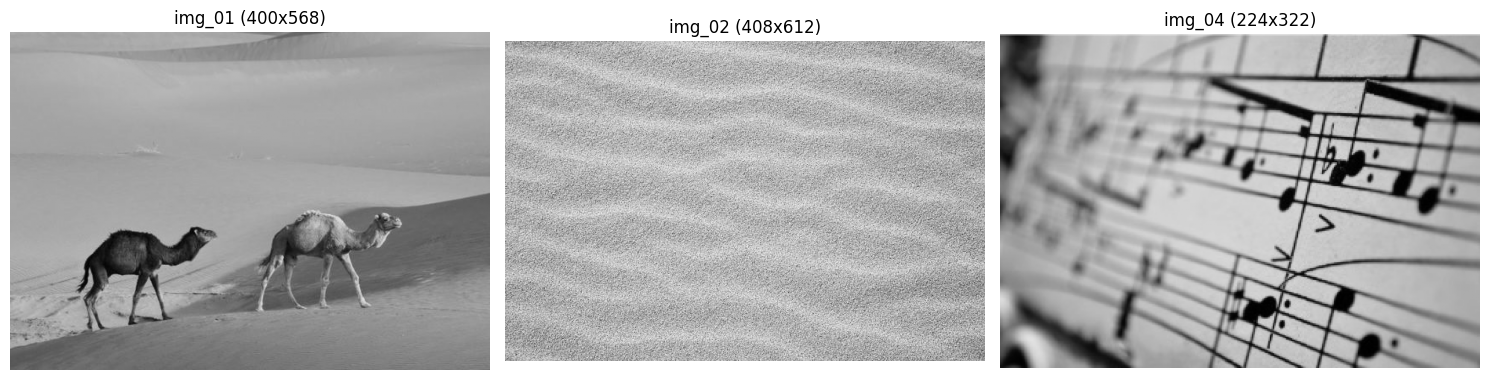

In [18]:
PATHS = ["img_01.jpg", "img_02.jpg", "img_04.jpg"]
imagenes = cargar_imagenes(PATHS)
mostrar_imagenes(imagenes)

## Ejercicio 1

### (a) Masa de probabilidad empírica y entropía

La masa de probabilidad se estima por frecuencia relativa:

$$\hat p(x) = \frac{n_x}{N}, \qquad x = 0, \dots, 255,$$

donde $n_x$ es la cantidad de píxeles con intensidad $x$ y $N$ el total de píxeles de la imagen.
La entropía (en bits) se calcula como

$$H(X) = -\sum_{x:\, \hat p(x) > 0} \hat p(x) \log_2 \hat p(x).$$

In [19]:
def estimar_probabilidad(simbolos: np.ndarray, alfabeto: np.ndarray | None = None) -> tuple[np.ndarray, np.ndarray]:
    """
    Estima la masa de probabilidad empírica de una fuente discreta.
    Argumentos:
    --simbolos: arreglo de enteros (cualquier forma). Para una imagen, la matriz de píxeles.
    --alfabeto: valores posibles de la fuente. Si es None se usa {0, ..., 255}.
    Retorno:
    --alfabeto: arreglo con los símbolos.
    --p: arreglo con p(x) = n_x / N para cada símbolo del alfabeto (mismo orden).
    """
    simbolos = np.asarray(simbolos).ravel().astype(np.int64)
    if alfabeto is None:
        alfabeto = np.arange(256)
    alfabeto = np.asarray(alfabeto)

    # Desplazamos para que el símbolo mínimo quede en 0 y poder usar bincount
    offset = alfabeto.min()
    conteos = np.bincount(simbolos - offset, minlength=alfabeto.max() - offset + 1)
    conteos = conteos[alfabeto - offset]
    p = conteos / simbolos.size
    return alfabeto, p


def entropia(p: np.ndarray) -> float:
    """
    Entropía en bits de una masa de probabilidad p. Ignora los términos con p(x) = 0.
    """
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))


def pmf_a_dict(alfabeto: np.ndarray, p: np.ndarray) -> dict[int, float]:
    """
    Convierte la pmf al formato {símbolo: probabilidad} que espera huffman_code,
    dejando afuera los símbolos de probabilidad nula.
    """
    return {int(x): float(px) for x, px in zip(alfabeto, p) if px > 0}


def graficar_pmf(alfabeto: np.ndarray, p: np.ndarray, titulo: str = "", ax=None, **kwargs):
    """
    Grafica la masa de probabilidad como barras. Si se pasa un eje (ax) dibuja ahí.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(alfabeto, p, width=1.0, **kwargs)
    ax.set_xlabel("símbolo")
    ax.set_ylabel("p")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    return ax

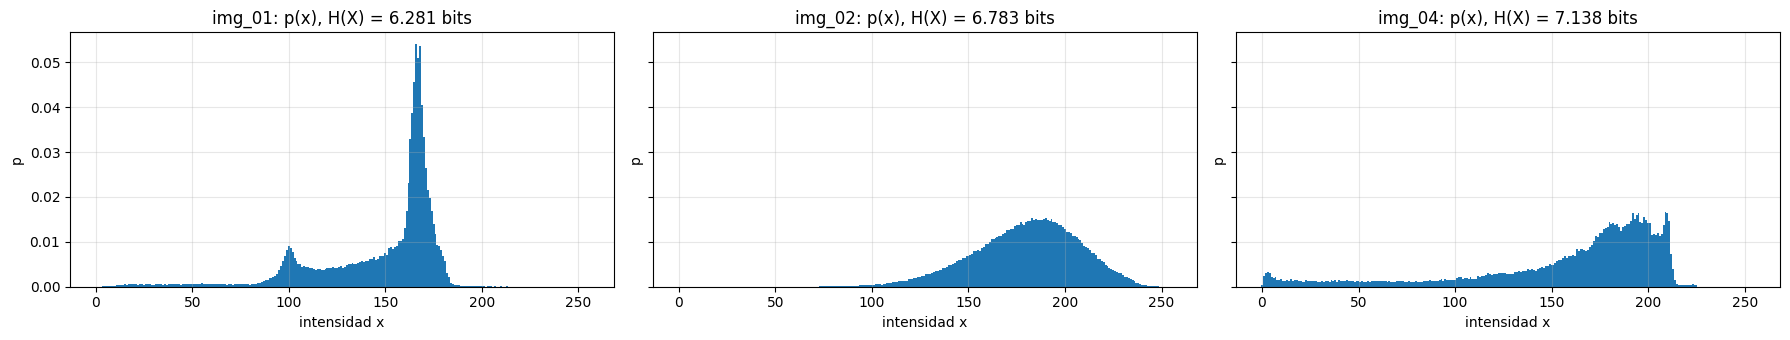

imagen       píxeles  niveles usados   H(X) [bits]
img_01        227200             224        6.2809
img_02        249696             205        6.7826
img_04         72128             228        7.1377


In [20]:
# Estimación de p(x) y H(X) para cada imagen
resultados_1a = {}
fig, axes = plt.subplots(1, len(imagenes), figsize=(6 * len(imagenes), 3.5), sharey=True)

for ax, (nombre, img) in zip(np.atleast_1d(axes), imagenes.items()):
    alfabeto, p_x = estimar_probabilidad(img)
    H_x = entropia(p_x)
    resultados_1a[nombre] = {"alfabeto": alfabeto, "p": p_x, "H": H_x}
    graficar_pmf(alfabeto, p_x, titulo=f"{nombre}: p(x), H(X) = {H_x:.3f} bits", ax=ax)
    ax.set_xlabel("intensidad x")

plt.tight_layout()
plt.show()

print(f"{'imagen':<10}{'píxeles':>10}{'niveles usados':>16}{'H(X) [bits]':>14}")
for nombre, r in resultados_1a.items():
    print(f"{nombre:<10}{imagenes[nombre].size:>10}{int((r['p'] > 0).sum()):>16}{r['H']:>14.4f}")

### (b) Compresión mediante código de Huffman

A partir de $\hat p(x)$ se construye el código de Huffman con la función provista por la cátedra.
Se codifica la imagen píxel a píxel y se mide la cantidad de **bits promedio por píxel** de la
cadena comprimida,

$$\bar\ell = \frac{\text{bits totales}}{N},$$

que se compara con la **longitud media teórica** del código,

$$L = \sum_x \hat p(x)\, l(x),$$

donde $l(x)$ es la longitud de la palabra de código asignada a $x$. Como $\hat p(x) = n_x / N$,
ambas cantidades deberían coincidir. Además se verifica la cota de Huffman

$$H(X) \le L < H(X) + 1.$$

In [21]:
def huffman_encode(simbolos: np.ndarray, codigo: dict[int, str]) -> str:
    """
    Codifica una secuencia de símbolos concatenando las palabras de código.
    Argumentos:
    --simbolos: arreglo de enteros (cualquier forma).
    --codigo: diccionario {símbolo: palabra de código} generado por huffman_code.
    Retorno:
    --Cadena de bits con la secuencia codificada.
    """
    return "".join(codigo[int(s)] for s in np.asarray(simbolos).ravel())


def longitud_media(alfabeto: np.ndarray, p: np.ndarray, codigo: dict[int, str]) -> float:
    """
    Longitud media teórica L = sum_x p(x) l(x) del código.
    """
    return float(sum(px * len(codigo[int(x)]) for x, px in zip(alfabeto, p) if px > 0))


def comprimir_huffman(simbolos: np.ndarray, alfabeto: np.ndarray | None = None) -> dict:
    """
    Pipeline completo: estima p, construye el código de Huffman, codifica, decodifica
    y verifica que la reconstrucción sea exacta.
    Retorno: diccionario con p, H, código, bits totales, bits promedio y L.
    """
    simbolos = np.asarray(simbolos)
    alfabeto, p = estimar_probabilidad(simbolos, alfabeto)
    H = entropia(p)
    codigo = aux.huffman_code(pmf_a_dict(alfabeto, p))

    bits = huffman_encode(simbolos, codigo)
    bits_totales = len(bits)
    bits_promedio = bits_totales / simbolos.size
    L = longitud_media(alfabeto, p, codigo)

    # Verificación de compresión sin pérdida
    decodificado = np.array(aux.huffman_decode(bits, codigo)).reshape(simbolos.shape)
    assert np.array_equal(decodificado, simbolos), "La decodificación no reconstruye la secuencia original"

    return {
        "alfabeto": alfabeto, "p": p, "H": H, "codigo": codigo,
        "bits_totales": bits_totales, "bits_promedio": bits_promedio, "L": L,
    }

In [22]:
resultados_1b = {nombre: comprimir_huffman(img) for nombre, img in imagenes.items()}

print(f"{'imagen':<10}{'H(X)':>9}{'L':>9}{'bits/píxel':>12}{'H(X)+1':>9}{'H<=L<H+1':>10}{'8/L':>8}")
for nombre, r in resultados_1b.items():
    cumple = r["H"] <= r["L"] < r["H"] + 1
    print(f"{nombre:<10}{r['H']:>9.4f}{r['L']:>9.4f}{r['bits_promedio']:>12.4f}"
          f"{r['H'] + 1:>9.4f}{str(cumple):>10}{8 / r['L']:>8.3f}")

imagen         H(X)        L  bits/píxel   H(X)+1  H<=L<H+1     8/L
img_01       6.2809   6.3100      6.3100   7.2809      True   1.268
img_02       6.7826   6.8092      6.8092   7.7826      True   1.175
img_04       7.1377   7.1651      7.1651   8.1377      True   1.117


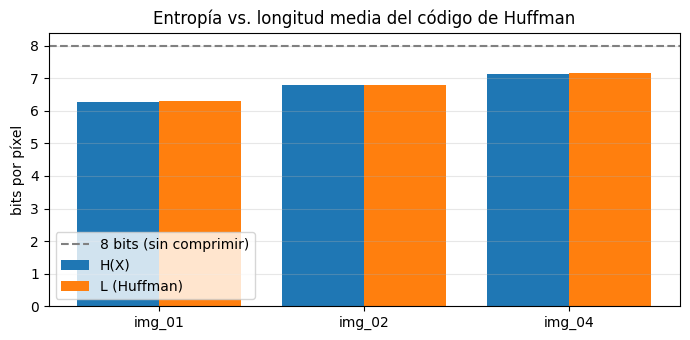

In [23]:
# Comparación gráfica: entropía, longitud media del código y representación directa
nombres = list(resultados_1b)
H = [resultados_1b[n]["H"] for n in nombres]
L = [resultados_1b[n]["L"] for n in nombres]
x = np.arange(len(nombres))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(x - 0.2, H, width=0.4, label="H(X)")
ax.bar(x + 0.2, L, width=0.4, label="L (Huffman)")
ax.axhline(8, color="gray", ls="--", label="8 bits (sin comprimir)")
ax.set_xticks(x, nombres)
ax.set_ylabel("bits por píxel")
ax.set_title("Entropía vs. longitud media del código de Huffman")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

**Observación.** Los bits promedio medidos sobre la cadena comprimida coinciden exactamente
con la longitud media teórica $L$, como era de esperar: $L = \sum_x \hat p(x)\, l(x) = \frac{1}{N}\sum_x n_x\, l(x)$,
que es la cuenta de bits totales dividida por $N$.

En las tres imágenes se cumple la cota de Huffman $H(X) \le L < H(X) + 1$. El código de Huffman es el
código libre de prefijo óptimo para una fuente sin memoria con esa pmf, pero como las longitudes $l(x)$
son enteras no puede alcanzar exactamente la entropía (eso requeriría $l(x) = -\log_2 p(x)$, que en general
no es entero). La diferencia $L - H(X)$ es la redundancia del código, y en este caso queda bastante por
debajo del bit de margen que garantiza la cota.

Respecto de la representación directa de 8 bits por píxel, la compresión lograda es modesta
(tasa $8/L$ entre 1.1 y 1.3 aproximadamente), porque la pmf de las intensidades está bastante repartida
entre muchos niveles de gris. Esto motiva el ejercicio 2: explotar la dependencia entre píxeles vecinos,
que la codificación píxel a píxel ignora por completo.

## Ejercicio 2

### (a) Residuos: masa de probabilidad y entropía

Se recorre la imagen en **serpentina**: la fila 0 de izquierda a derecha, la fila 1 de derecha a izquierda,
y así sucesivamente. De este modo toda la imagen queda como una única secuencia $x_1, \dots, x_{MN}$ en la
que cada píxel es vecino espacial del anterior, se guarda un único píxel inicial $x_1$ y el resto se
representa con residuos

$$y_k = x_k - x_{k-1}, \qquad k = 2, \dots, MN, \qquad y_k \in \{-255, \dots, 255\}.$$

La reconstrucción es $x_k = x_{k-1} + y_k$ partiendo de $x_1$. Sobre la fuente $Y$ se estima $\hat p(y)$ y se
calcula $H(Y)$ con las mismas funciones del ejercicio 1, usando como alfabeto $\{-255, \dots, 255\}$.

In [24]:
ALFABETO_RESIDUOS = np.arange(-255, 256)


def serpentina(img: np.ndarray) -> np.ndarray:
    """
    Aplana la imagen recorriéndola en serpentina (filas impares invertidas).
    """
    s = img.copy()
    s[1::2] = s[1::2, ::-1]
    return s.ravel()


def deshacer_serpentina(secuencia: np.ndarray, shape: tuple[int, int]) -> np.ndarray:
    """
    Inversa de serpentina: reconstruye la matriz a partir de la secuencia.
    """
    img = secuencia.reshape(shape).copy()
    img[1::2] = img[1::2, ::-1]
    return img


def calcular_residuos(img: np.ndarray) -> tuple[int, np.ndarray]:
    """
    Calcula los residuos y_k = x_k - x_{k-1} sobre el recorrido en serpentina.
    Retorno:
    --inicial: intensidad del primer píxel (condición inicial).
    --residuos: arreglo de enteros en [-255, 255] de longitud M*N - 1.
    """
    seq = serpentina(img).astype(np.int64)
    return int(seq[0]), np.diff(seq)


def reconstruir_desde_residuos(inicial: int, residuos: np.ndarray, shape: tuple[int, int]) -> np.ndarray:
    """
    Reconstruye la imagen sumando sucesivamente los residuos al píxel anterior.
    """
    seq = np.concatenate([[inicial], residuos]).cumsum()
    return deshacer_serpentina(seq, shape).astype(np.uint8)

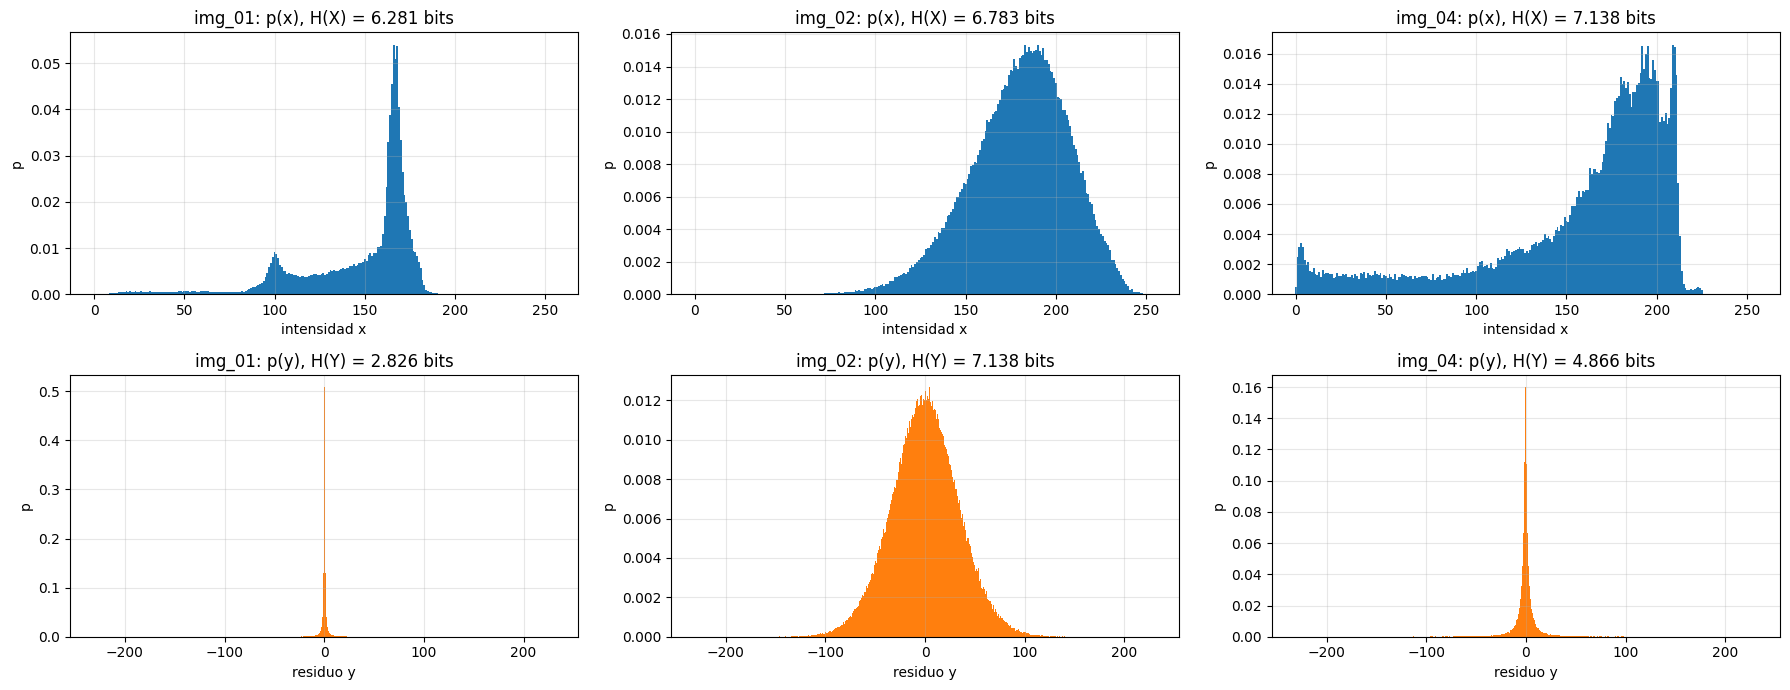

imagen         H(X)     H(Y)  H(X)-H(Y)   |y|<=5  niveles y
img_01       6.2809   2.8262     3.4546    0.925        230
img_02       6.7826   7.1379    -0.3553    0.134        303
img_04       7.1377   4.8659     2.2719    0.719        311


In [25]:
resultados_2a = {}
fig, axes = plt.subplots(2, len(imagenes), figsize=(6 * len(imagenes), 7))

for col, (nombre, img) in enumerate(imagenes.items()):
    inicial, residuos = calcular_residuos(img)
    assert np.array_equal(reconstruir_desde_residuos(inicial, residuos, img.shape), img)

    alfabeto_y, p_y = estimar_probabilidad(residuos, ALFABETO_RESIDUOS)
    H_y = entropia(p_y)
    resultados_2a[nombre] = {"inicial": inicial, "residuos": residuos,
                             "alfabeto": alfabeto_y, "p": p_y, "H": H_y}

    r1 = resultados_1a[nombre]
    graficar_pmf(r1["alfabeto"], r1["p"], titulo=f"{nombre}: p(x), H(X) = {r1['H']:.3f} bits", ax=axes[0, col])
    axes[0, col].set_xlabel("intensidad x")
    graficar_pmf(alfabeto_y, p_y, titulo=f"{nombre}: p(y), H(Y) = {H_y:.3f} bits", ax=axes[1, col], color="C1")
    axes[1, col].set_xlabel("residuo y")
    axes[1, col].set_xlim(-255, 255)

plt.tight_layout()
plt.show()

print(f"{'imagen':<10}{'H(X)':>9}{'H(Y)':>9}{'H(X)-H(Y)':>11}{'|y|<=5':>9}{'niveles y':>11}")
for nombre, r in resultados_2a.items():
    p_centro = r["p"][np.abs(r["alfabeto"]) <= 5].sum()
    print(f"{nombre:<10}{resultados_1a[nombre]['H']:>9.4f}{r['H']:>9.4f}"
          f"{resultados_1a[nombre]['H'] - r['H']:>11.4f}{p_centro:>9.3f}{int((r['p'] > 0).sum()):>11}")

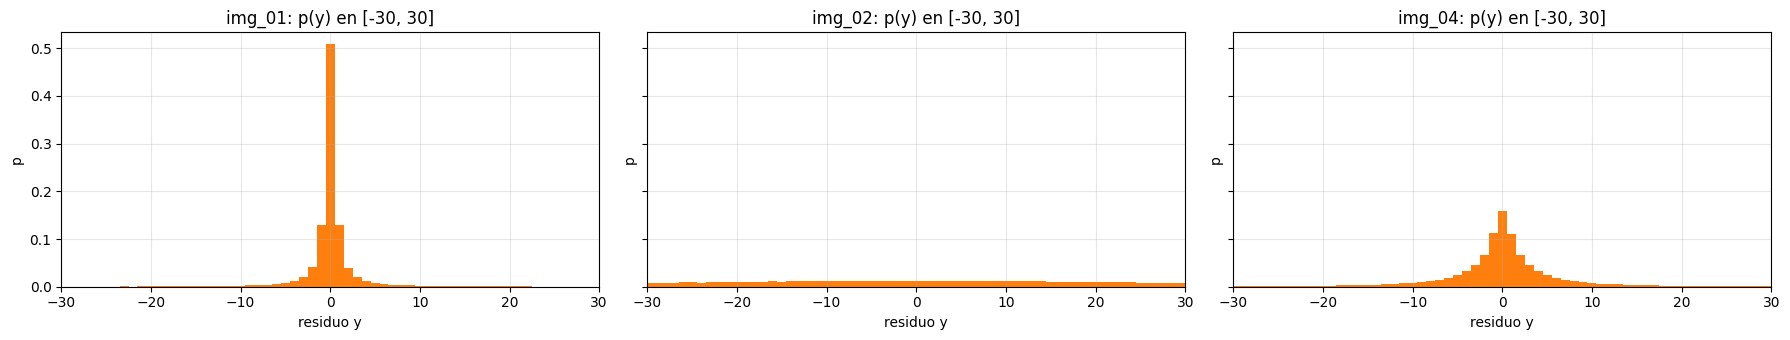

In [26]:
# Zoom sobre la zona central de p(y), donde se concentra casi toda la masa
fig, axes = plt.subplots(1, len(imagenes), figsize=(6 * len(imagenes), 3.5), sharey=True)
for ax, (nombre, r) in zip(np.atleast_1d(axes), resultados_2a.items()):
    graficar_pmf(r["alfabeto"], r["p"], titulo=f"{nombre}: p(y) en [-30, 30]", ax=ax, color="C1")
    ax.set_xlim(-30, 30)
    ax.set_xlabel("residuo y")
plt.tight_layout()
plt.show()

**Observación.** El comportamiento no es el mismo en las tres imágenes:

- En **img_01** (dunas, grandes regiones suaves) y en **img_04** (partitura, fondo uniforme con trazos negros)
  la pmf de los residuos está fuertemente concentrada en $y = 0$ y decae rápido hacia los extremos: más del 90 %
  y del 70 % de los residuos, respectivamente, caen en $|y| \le 5$. En consecuencia $H(Y)$ es bastante menor que
  $H(X)$, aun cuando el alfabeto de $Y$ (511 símbolos) es el doble de grande que el de $X$ (256). Es la
  redundancia espacial: como los píxeles vecinos tienen intensidades parecidas, la diferencia entre ellos es
  pequeña y mucho más predecible que el valor absoluto del píxel.

- En **img_02** (textura de arena, grano fino) ocurre lo contrario: $H(Y) > H(X)$. Solo el 13 % de los residuos
  cae en $|y| \le 5$ y la pmf de $Y$ es ancha. A escala de un píxel la arena se comporta como ruido: la
  intensidad de un píxel aporta poca información sobre la del vecino, y restarlos no reduce la variabilidad
  sino que la amplifica (la diferencia de dos variables casi independientes tiene mayor dispersión que cada
  una por separado). La codificación diferencial solo ayuda cuando existe dependencia entre vecinos, lo que se
  cuantifica en el inciso (c) con la información mutua $I(X; X')$.

### (b) Compresión de los residuos mediante Huffman

Se aplica el mismo pipeline del ejercicio 1(b) (`comprimir_huffman`) sobre la fuente $Y$ de residuos,
usando como alfabeto $\{-255, \dots, 255\}$. Se mide la cantidad de bits promedio por residuo y se compara
con la longitud media teórica $L_Y = \sum_y \hat p(y)\, l(y)$, verificando además $H(Y) \le L_Y < H(Y) + 1$.

Para que la comparación con el ejercicio 1 sea justa se calcula también el **costo total por píxel**, que
incluye los 8 bits del píxel inicial de la serpentina:

$$\text{bits/píxel}_{\text{total}} = \frac{8 + \text{bits de los residuos}}{MN}.$$

In [27]:
resultados_2b = {}
for nombre, r in resultados_2a.items():
    res = comprimir_huffman(r["residuos"], ALFABETO_RESIDUOS)
    N = imagenes[nombre].size
    res["bits_totales_imagen"] = 8 + res["bits_totales"]          # píxel inicial + residuos
    res["bits_por_pixel"] = res["bits_totales_imagen"] / N
    resultados_2b[nombre] = res

print(f"{'imagen':<10}{'H(Y)':>9}{'L_Y':>9}{'bits/res':>10}{'H<=L<H+1':>10}"
      f"{'bits/píx':>10}{'L_X (ej1)':>11}{'tasa ej1':>10}{'tasa ej2':>10}")
for nombre, r in resultados_2b.items():
    cumple = r["H"] <= r["L"] < r["H"] + 1
    L_x = resultados_1b[nombre]["L"]
    print(f"{nombre:<10}{r['H']:>9.4f}{r['L']:>9.4f}{r['bits_promedio']:>10.4f}{str(cumple):>10}"
          f"{r['bits_por_pixel']:>10.4f}{L_x:>11.4f}{8 / L_x:>10.3f}{8 / r['bits_por_pixel']:>10.3f}")

imagen         H(Y)      L_Y  bits/res  H<=L<H+1  bits/píx  L_X (ej1)  tasa ej1  tasa ej2
img_01       2.8262   2.8402    2.8402      True    2.8402     6.3100     1.268     2.817
img_02       7.1379   7.1788    7.1788      True    7.1788     6.8092     1.175     1.114
img_04       4.8659   4.8936    4.8936      True    4.8937     7.1651     1.117     1.635


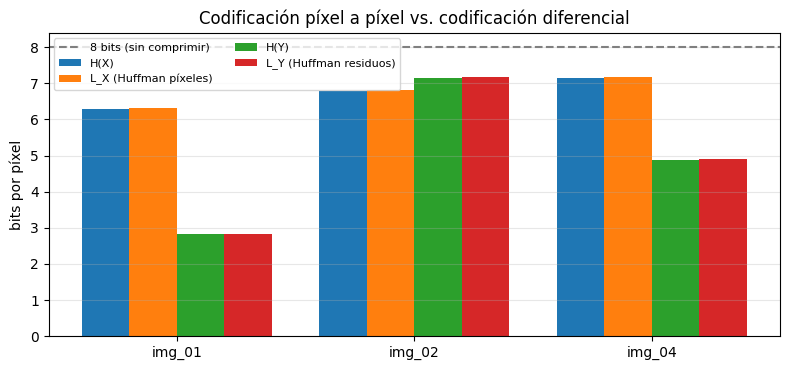

In [28]:
# Comparación: entropías y longitudes medias, píxel a píxel vs. residuos
nombres = list(resultados_2b)
x = np.arange(len(nombres))
w = 0.2
series = [
    ("H(X)", [resultados_1b[n]["H"] for n in nombres]),
    ("L_X (Huffman píxeles)", [resultados_1b[n]["L"] for n in nombres]),
    ("H(Y)", [resultados_2b[n]["H"] for n in nombres]),
    ("L_Y (Huffman residuos)", [resultados_2b[n]["bits_por_pixel"] for n in nombres]),
]

fig, ax = plt.subplots(figsize=(8, 3.8))
for k, (etiqueta, valores) in enumerate(series):
    ax.bar(x + (k - 1.5) * w, valores, width=w, label=etiqueta)
ax.axhline(8, color="gray", ls="--", label="8 bits (sin comprimir)")
ax.set_xticks(x, nombres)
ax.set_ylabel("bits por píxel")
ax.set_title("Codificación píxel a píxel vs. codificación diferencial")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

**Observación.** Nuevamente los bits promedio medidos coinciden con la longitud media teórica $L_Y$ y se
cumple $H(Y) \le L_Y < H(Y) + 1$ en las tres imágenes. El sobrecosto del píxel inicial (8 bits sobre toda la
imagen) es despreciable, por lo que el costo total por píxel es prácticamente igual a $L_Y$.

La ganancia de la codificación diferencial sigue exactamente lo que anticipaban las entropías:

- En **img_01** la tasa de compresión pasa de $\approx 1.27$ a $\approx 2.8$, y en **img_04** de $\approx 1.12$
  a $\approx 1.6$. Como $\hat p(y)$ está concentrada en pocos símbolos, Huffman asigna palabras de 1 a 3 bits
  a los residuos cercanos a cero, que son la gran mayoría.
- En **img_02** la codificación de residuos es **peor** que la píxel a píxel ($L_Y > L_X$): la textura de arena
  no tiene redundancia espacial aprovechable y los residuos están más dispersos que las intensidades.

En todos los casos Huffman queda a menos de 0.05 bits de la entropía de la fuente que codifica. El método es
óptimo para una fuente sin memoria; lo que cambia entre los dos esquemas no es el codificador sino la fuente,
y la codificación diferencial solo construye una fuente de menor entropía cuando los píxeles vecinos están
correlacionados.

### (c) Información mutua entre píxeles vecinos

Se toman los mismos pares que se usaron para los residuos: sobre la secuencia en serpentina
$x_1, \dots, x_{MN}$, cada par es $(x', x) = (x_{k-1}, x_k)$, con $X'$ el píxel anterior y $X$ el actual.
La pmf conjunta $\hat p(x, x')$ se estima con el histograma bidimensional de $256 \times 256$ bins,
y la información mutua se calcula como

$$I(X; X') = \sum_{x, x'} \hat p(x, x') \log_2 \frac{\hat p(x, x')}{\hat p(x)\, \hat p(x')} = H(X) + H(X') - H(X, X').$$

$I(X; X')$ mide cuántos bits de incerteza sobre un píxel se eliminan al conocer su vecino. Se relaciona con
la codificación diferencial porque $H(X \mid X') = H(X) - I(X; X')$ es la entropía que queda una vez conocido
el vecino, y el residuo $Y = X - X'$ es una función de $(X, X')$, por lo que $H(Y) \ge H(X \mid X')$.

**Aclaración.** Las entropías $H(X)$ y $H(X')$ de este inciso se calculan sobre las secuencias de los pares,
que tienen $MN - 1$ muestras cada una: $X'$ recorre los píxeles sin el último y $X$ los píxeles sin el primero.
No son exactamente la $H(X)$ del ejercicio 1, que usa los $MN$ píxeles, aunque difieren en un solo píxel y
coinciden en todas las cifras mostradas. Se hace así para que $I = H(X) + H(X') - H(X, X')$ use las mismas
muestras en los tres términos.

In [29]:
def pares_vecinos(img: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Pares (x', x) de píxeles vecinos consecutivos en el recorrido en serpentina,
    los mismos pares con los que se calcularon los residuos.
    """
    seq = serpentina(img).astype(np.int64)
    return seq[:-1], seq[1:]


def informacion_mutua(a: np.ndarray, b: np.ndarray, n_niveles: int = 256) -> dict:
    """
    Estima empíricamente I(A; B) = H(A) + H(B) - H(A, B) para dos secuencias de
    enteros en {0, ..., n_niveles - 1} de igual longitud.
    Retorno: diccionario con la pmf conjunta y las entropías involucradas.
    """
    # La pmf conjunta se estima reutilizando estimar_probabilidad sobre el índice
    # combinado a * n_niveles + b, que identifica cada par (a, b) con un entero.
    _, p_conjunta = estimar_probabilidad(a * n_niveles + b, np.arange(n_niveles ** 2))
    p_conjunta = p_conjunta.reshape(n_niveles, n_niveles)

    _, p_a = estimar_probabilidad(a, np.arange(n_niveles))
    _, p_b = estimar_probabilidad(b, np.arange(n_niveles))

    H_a, H_b, H_ab = entropia(p_a), entropia(p_b), entropia(p_conjunta)
    return {"p_conjunta": p_conjunta, "H_a": H_a, "H_b": H_b, "H_ab": H_ab, "I": H_a + H_b - H_ab}

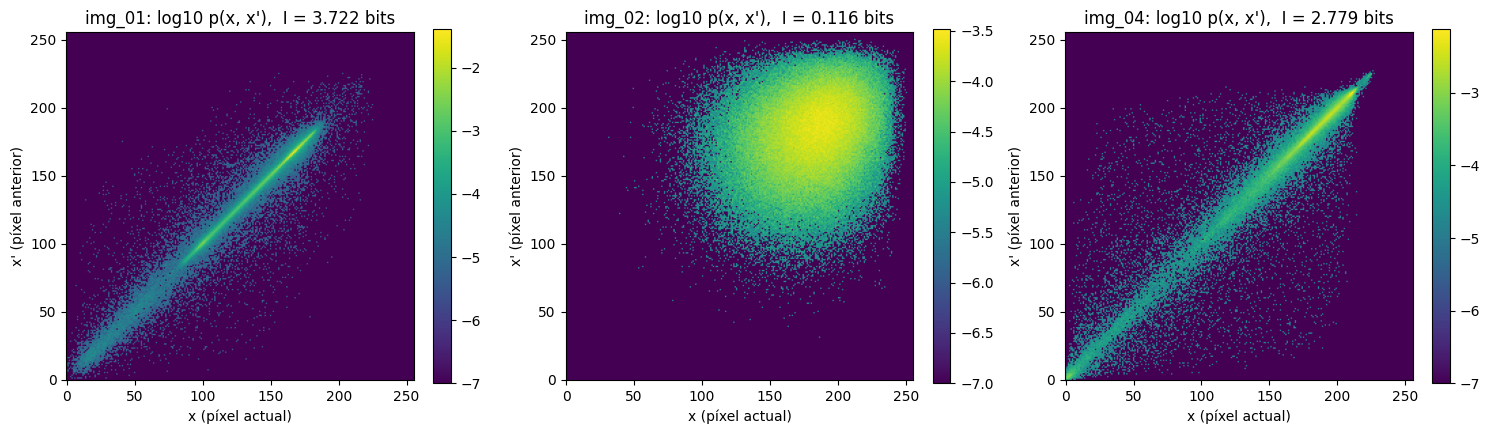

imagen        H(X)  H(X,X´)  I(X;X´)  I/H(X)  H(X|X´)    H(Y)  H(X)-H(Y)
img_01      6.2809   8.8401   3.7217   0.593   2.5592  2.8262     3.4546
img_02      6.7826  13.4495   0.1157   0.017   6.6669  7.1379    -0.3553
img_04      7.1377  11.4959   2.7794   0.389   4.3583  4.8659     2.2718


In [30]:
resultados_2c = {}
fig, axes = plt.subplots(1, len(imagenes), figsize=(5 * len(imagenes), 4.5))

for ax, (nombre, img) in zip(np.atleast_1d(axes), imagenes.items()):
    x_prev, x_act = pares_vecinos(img)
    r = informacion_mutua(x_prev, x_act)
    resultados_2c[nombre] = r

    # Solo para visualizar: p(x, x') abarca varios órdenes de magnitud y en escala lineal
    # únicamente se vería la diagonal. Se usa log10 porque la barra de color se lee directo
    # como órdenes de magnitud de probabilidad; no es un cálculo de información, para esos
    # (entropías e información mutua) se usa log2 y el resultado queda en bits.
    im = ax.imshow(np.log10(r["p_conjunta"] + 1e-7), origin="lower", cmap="viridis")
    ax.set_xlabel("x (píxel actual)")
    ax.set_ylabel("x' (píxel anterior)")
    ax.set_title(f"{nombre}: log10 p(x, x'),  I = {r['I']:.3f} bits")
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

print(f"{'imagen':<10}{'H(X)':>8}{'H(X,X´)':>9}{'I(X;X´)':>9}{'I/H(X)':>8}{'H(X|X´)':>9}{'H(Y)':>8}{'H(X)-H(Y)':>11}")
for nombre, r in resultados_2c.items():
    H_y = resultados_2a[nombre]["H"]
    H_cond = r["H_b"] - r["I"]
    print(f"{nombre:<10}{r['H_b']:>8.4f}{r['H_ab']:>9.4f}{r['I']:>9.4f}{r['I'] / r['H_b']:>8.3f}"
          f"{H_cond:>9.4f}{H_y:>8.4f}{r['H_b'] - H_y:>11.4f}")

**Observación.** La pmf conjunta muestra directamente la dependencia entre vecinos. En **img_01** y
**img_04** la masa se concentra sobre la diagonal $x = x'$: conocer el píxel anterior deja al actual casi
determinado, y la información mutua es alta (entre el 40 % y el 60 % de $H(X)$). En **img_02** la
nube es ancha y difusa alrededor de la diagonal: el vecino aporta poca información y $I(X; X')$ es baja.

Se verifica en las tres imágenes que $H(X) - H(Y) \le I(X; X')$, como corresponde a $H(Y) \ge H(X \mid X')$.
En las imágenes suaves los residuos capturan casi toda la información mutua, es decir, $H(Y)$ queda cerca
de $H(X \mid X')$. En img_02, en cambio, $I(X; X')$ es pequeña pero positiva mientras que $H(X) - H(Y)$ es
negativa: hay algo de dependencia entre vecinos, pero la resta $X - X'$ es un modo muy pobre de
aprovecharla cuando la correlación es débil, porque mezcla dos variables casi independientes y ensancha
la distribución. La información mutua acota lo que cualquier esquema basado en el vecino podría ganar; la
codificación diferencial es solo una forma particular, y no siempre eficiente, de hacerlo.

## Ejercicio 3

### (a) ¿A qué se deben las diferencias de entropía entre las imágenes?

| imagen | $H(X)$ [bits] | niveles usados | $\log_2(\text{niveles})$ |
|---|---|---|---|
| img_01 | 6.28 | 224 | 7.81 |
| img_02 | 6.78 | 205 | 7.68 |
| img_04 | 7.14 | 228 | 7.83 |

$H(X)$ depende únicamente de la forma de la pmf de intensidades: es máxima ($\log_2 M$) cuando los $M$ niveles
usados son equiprobables y disminuye cuanto más concentrada está la masa en pocos niveles. Las tres imágenes
usan una cantidad similar de niveles, de modo que la diferencia no está en el rango sino en cuán
repartida está la masa dentro de él.

- **img_01** tiene la entropía más baja porque la mayor parte de la imagen es arena de un tono similar:
  la pmf tiene un pico pronunciado entre 100 y 190 y poca masa fuera de él.
- **img_02** usa menos niveles, pero dentro de la zona 120 a 240 la masa está repartida de manera bastante
  pareja, por lo que su entropía es mayor que la de img_01.
- **img_04** tiene la entropía más alta porque combina dos poblaciones bien separadas (fondo claro y tinta
  oscura) con transiciones entre ambas, lo que cubre casi todo el rango 0 a 230 con una pmf relativamente plana.

En resumen: la entropía refleja el contraste y la variedad tonal de la imagen, no su textura ni su
estructura espacial, que la pmf de intensidades ignora por completo.

### (b) ¿Qué representa la información mutua y a qué se deben sus diferencias?

| imagen | $I(X;X')$ [bits] | $I/H(X)$ | $H(X \mid X')$ | $H(Y)$ |
|---|---|---|---|---|
| img_01 | 3.72 | 0.59 | 2.56 | 2.83 |
| img_02 | 0.12 | 0.02 | 6.67 | 7.14 |
| img_04 | 2.78 | 0.39 | 4.36 | 4.87 |

$I(X;X')$ mide cuántos bits de incerteza sobre un píxel se eliminan al conocer su vecino: es la
**redundancia espacial** de la imagen. Para la codificación diferencial es la cantidad máxima de bits por
píxel que cualquier esquema basado en el vecino podría ahorrar, porque $H(X \mid X') = H(X) - I(X;X')$ es
lo mínimo que hay que codificar una vez conocido $X'$, y los residuos cumplen $H(Y) \ge H(X \mid X')$.

Las diferencias entre imágenes se deben a cuán parecidos son los píxeles vecinos, es decir, a la
**suavidad** de la imagen a escala de un píxel:

- **img_01** es la más suave (grandes regiones de dunas con variación gradual): conocer el vecino elimina
  el 59 % de la incerteza. En la pmf conjunta la masa se concentra en una diagonal fina.
- **img_04** tiene regiones uniformes (fondo, interior de las notas) pero también muchos bordes de tinta
  que generan pares muy distintos; la diagonal es nítida pero con más dispersión, y $I$ es menor.
- **img_02** es una textura de grano fino: la intensidad de un píxel casi no dice nada sobre la del vecino,
  la pmf conjunta no muestra estructura diagonal y $I$ es casi nula. Es decir, la imagen tiene mucha
  variabilidad (entropía alta) pero casi nada de ella es redundancia aprovechable.

### (c) ¿Qué diferencias hay entre la compresión píxel a píxel y la de residuos, y a qué se deben?

| imagen | $L_X$ | $L_Y$ | tasa píxel a píxel | tasa residuos |
|---|---|---|---|---|
| img_01 | 6.31 | 2.84 | 1.27 | 2.82 |
| img_02 | 6.81 | 7.18 | 1.17 | 1.11 |
| img_04 | 7.17 | 4.89 | 1.12 | 1.63 |

En ambos esquemas Huffman queda a menos de 0.05 bits de la entropía de la fuente que codifica, con lo que el
codificador no es lo que cambia: lo que cambia es la **fuente**. La codificación píxel a píxel trata a cada
píxel como independiente de los demás y su límite es $H(X)$, que no puede aprovechar la dependencia
espacial. La codificación diferencial transforma la imagen en una fuente $Y$ cuya entropía puede ser mucho
menor que $H(X)$ cuando los vecinos están correlacionados.

- En **img_01** e **img_04** la pmf de los residuos se concentra alrededor de cero (92 % y 72 % de los
  residuos en $|y| \le 5$), Huffman asigna palabras de 1 a 3 bits a esos símbolos y la tasa de compresión
  pasa de 1.27 a 2.82 y de 1.12 a 1.63 respectivamente. La ganancia $L_X - L_Y$ es cercana a $I(X;X')$,
  es decir, los residuos capturan casi toda la redundancia espacial disponible.
- En **img_02** la compresión de residuos es **peor** que la píxel a píxel. Al no haber dependencia entre
  vecinos ($I \approx 0.1$ bits), restar dos píxeles casi independientes produce una variable con más
  dispersión que cada uno por separado, y $H(Y) > H(X)$.

La diferencia entre ambos métodos se debe entonces a la redundancia espacial de cada imagen: la
codificación diferencial gana exactamente en la medida en que $I(X;X')$ es grande, y pierde cuando es
cercana a cero.

### Posibles extensiones

- **Predictores mejores.** El residuo contra el vecino de la izquierda es el predictor más simple. Usar
  el vecino de arriba, el promedio de ambos o el predictor de Paeth (como hace PNG) reduce $H(Y)$ en
  imágenes con estructura vertical, y en img_02 se podría probar si algún predictor supera a la codificación
  píxel a píxel.
- **Dependencia más allá del vecino inmediato.** Estimar $I(X; X'')$ con el píxel a distancia 2 o con el
  de la fila anterior para cuantificar cuánta redundancia queda sin explotar por el esquema diferencial.
- **Entropía condicional directa.** Codificar $X$ con un código de Huffman distinto para cada valor de
  $X'$ (codificación condicional) alcanza $H(X \mid X')$ en lugar de $H(Y)$, a costa de 256 tablas.
- **Costo de la tabla de códigos.** En el ejercicio 4 el archivo debe incluir el diccionario de Huffman;
  medir cuánto pesa frente a los datos, sobre todo en imágenes chicas como img_04.
- **Bloques de símbolos.** Codificar pares de píxeles o de residuos como un único símbolo reduce la
  redundancia de Huffman ($L - H$) y captura parte de la dependencia entre símbolos consecutivos.